In [12]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))

In [3]:
import pandas as pd

a = pd.read_csv(ROOT / "data/attributes.csv")
g = pd.read_csv(ROOT / "data/classified.csv")[["folder", "file", "garment"]]
a = a.drop(columns=["garment"], errors="ignore").merge(g, on=["folder", "file"], how="left")
a.to_csv(ROOT / "data/attributes.csv", index=False)

def summary(df):
    return {
        "photos": len(df),
        "garments": df["garment"].value_counts(normalize=True).round(2).to_dict(),
        "top_colors": df["color_upper"].value_counts(normalize=True).head(3).round(2).to_dict(),
        "patterns": df["pattern_final"].value_counts(normalize=True).round(2).to_dict(),
    }

for brand, d in a.groupby("brand"):
    print(brand, summary(d), "\n")

chloe {'photos': 60, 'garments': {'dresses': 0.48, 'outerwear': 0.27, 'bottoms': 0.1, 'tops': 0.1, 'knitwear': 0.05}, 'top_colors': {'white': 0.27, 'black': 0.23, 'light pink': 0.18}, 'patterns': {'solid / other': 0.47, 'solid': 0.33, 'floral': 0.15, 'animal print': 0.03, 'polka dots': 0.02}} 

escvdo {'photos': 52, 'garments': {'dresses': 0.65, 'knitwear': 0.19, 'bottoms': 0.1, 'tops': 0.06}, 'top_colors': {'black': 0.23, 'grey': 0.23, 'beige': 0.19}, 'patterns': {'striped': 0.35, 'solid / other': 0.31, 'solid': 0.19, 'animal print': 0.08, 'polka dots': 0.06, 'checked': 0.02}} 



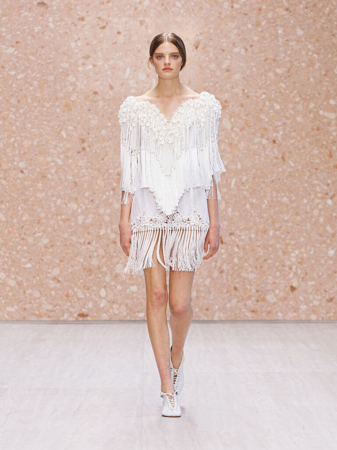

60/60 | 060.jpg


In [3]:
import pandas as pd
from IPython.display import display, clear_output
from PIL import Image

KEYS = {"t": "tops", "b": "bottoms", "d": "dresses", "k": "knitwear", "o": "outerwear"}
path = ROOT / "data/chloe_labels_FINAL.csv"

if not path.exists():                       # solo se crea la primera vez
    c = pd.read_csv(ROOT / "data/chloe_all.csv")
    tpl = c[["folder", "file"]].copy()
    tpl["labels_manual"] = ""
    tpl.to_csv(path, index=False)

tpl = pd.read_csv(path)
tpl["labels_manual"] = tpl["labels_manual"].fillna("")

for i, r in tpl.iterrows():
    if r["labels_manual"]:
        continue
    img = Image.open(ROOT / "images" / r["folder"] / r["file"]).convert("RGB")
    img.thumbnail((450, 450))
    clear_output(wait=True)
    display(img)
    print(f"{i + 1}/{len(tpl)} | {r['file']}")
    ans = input("t b d k o (ej: kb) | x=no es un look | s=salir > ")
    if ans == "s":
        break
    tpl.at[i, "labels_manual"] = "none" if "x" in ans else "|".join(KEYS[c] for c in ans if c in KEYS)
    tpl.to_csv(path, index=False)

In [4]:
import numpy as np
import pandas as pd
from classify import get_embedding

e = pd.read_csv(ROOT / "data/escvdo_labels_FINAL.csv")[["folder", "file", "labels_manual"]]
c = pd.read_csv(ROOT / "data/chloe_labels_FINAL.csv")[["folder", "file", "labels_manual"]]
d = pd.concat([e, c], ignore_index=True)
d["labels_manual"] = d["labels_manual"].fillna("")
d = d[(d["labels_manual"] != "") & (d["labels_manual"] != "none")].reset_index(drop=True)

X = np.array([get_embedding(ROOT / "images" / r.folder / r.file) for r in d.itertuples()])
np.save(ROOT / "data/all_embeddings.npy", X)
d.to_csv(ROOT / "data/all_labels.csv", index=False)
print(X.shape)

/Users/gloriamorales/Documents/Agent_AI/escvdo-trend-agent/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1115 23:49:01.180000 56285 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 41610.57it/s]


(105, 512)


In [5]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score

d = pd.read_csv(ROOT / "data/all_labels.csv")
X = np.load(ROOT / "data/all_embeddings.npy")

classes = ["tops", "bottoms", "dresses", "knitwear", "outerwear"]
Y = np.array([[c in l.split("|") for c in classes] for l in d["labels_manual"]]).astype(int)

P = np.zeros(Y.shape)
for train, test in KFold(5, shuffle=True, random_state=0).split(X):
    for j in range(len(classes)):
        y = Y[train, j]
        if y.min() == y.max():
            P[test, j] = y[0]
        else:
            clf = LogisticRegression(C=10, max_iter=1000, class_weight="balanced")
            clf.fit(X[train], y)
            P[test, j] = clf.predict_proba(X[test])[:, 1]

pred = pd.read_csv(ROOT / "data/classified.csv")[["folder", "file", "garment"]]
clip = d.merge(pred, on=["folder", "file"], how="left")["garment"]
C = np.array([[g == c for c in classes] for g in clip]).astype(int)

res = pd.DataFrame({
    "fotos_con_la_prenda": Y.sum(axis=0),
    "clip_puro": [f1_score(Y[:, j], C[:, j], zero_division=0) for j in range(5)],
    "modelo_entrenado": [f1_score(Y[:, j], P[:, j] > 0.5, zero_division=0) for j in range(5)],
}, index=classes).round(2)
res

,fotos_con_la_prenda,clip_puro,modelo_entrenado
tops,27,0.36,0.46
bottoms,20,0.13,0.25
dresses,35,0.62,0.62
knitwear,48,0.27,0.95
outerwear,23,0.72,0.86


In [6]:
import pandas as pd

a = pd.read_csv(ROOT / "data/attributes.csv").drop(columns=["garment"], errors="ignore")
e = pd.read_csv(ROOT / "data/escvdo_labels_FINAL.csv")[["folder", "file", "labels_manual"]]
c = pd.read_csv(ROOT / "data/chloe_labels_FINAL.csv")[["folder", "file", "labels_manual"]]
labels = pd.concat([e, c])
a = a.merge(labels, on=["folder", "file"], how="left")
a = a[a["labels_manual"].notna() & (a["labels_manual"] != "none")]
a.to_csv(ROOT / "data/final_table.csv", index=False)

garments = ["knitwear", "tops", "dresses", "bottoms", "outerwear"]

def summary(df):
    s = {"photos": len(df)}
    for g in garments:
        s[g] = round(df["labels_manual"].str.split("|").apply(lambda x: g in x).mean(), 2)
    s["top_colors"] = df["color_upper"].value_counts(normalize=True).head(3).round(2).to_dict()
    s["patterns"] = df["pattern_final"].value_counts(normalize=True).round(2).to_dict()
    return s

for brand, d in a.groupby("brand"):
    print(brand, summary(d), "\n")

chloe {'photos': 53, 'knitwear': np.float64(0.0), 'tops': np.float64(0.23), 'dresses': np.float64(0.3), 'bottoms': np.float64(0.09), 'outerwear': np.float64(0.38), 'top_colors': {'white': 0.28, 'black': 0.25, 'light pink': 0.21}, 'patterns': {'solid / other': 0.45, 'solid': 0.34, 'floral': 0.17, 'animal print': 0.02, 'polka dots': 0.02}} 

escvdo {'photos': 52, 'knitwear': np.float64(0.92), 'tops': np.float64(0.29), 'dresses': np.float64(0.37), 'bottoms': np.float64(0.29), 'outerwear': np.float64(0.06), 'top_colors': {'black': 0.23, 'grey': 0.23, 'beige': 0.19}, 'patterns': {'striped': 0.35, 'solid / other': 0.31, 'solid': 0.19, 'animal print': 0.08, 'polka dots': 0.06, 'checked': 0.02}} 



In [7]:
from insights import phrase_fact

garments = ["knitwear", "tops", "dresses", "bottoms", "outerwear"]

def facts(own_df, comp_df, own_name, comp_name, n=5):
    rows = []
    for g in garments:
        po = own_df["labels_manual"].str.split("|").apply(lambda x: g in x).mean()
        pc = comp_df["labels_manual"].str.split("|").apply(lambda x: g in x).mean()
        rows.append((abs(po - pc), f"fotos con {g}", po, pc))
    for col, label in [("color_upper", "color de la parte de arriba"), ("pattern_final", "patrón")]:
        so = own_df[col].value_counts(normalize=True)
        sc = comp_df[col].value_counts(normalize=True)
        for v in set(so.index) | set(sc.index):
            if v == "solid / other":
                continue
            po, pc = so.get(v, 0), sc.get(v, 0)
            rows.append((abs(po - pc), f"{label} {v}", po, pc))
    rows.sort(reverse=True)
    return [f"{k}: {own_name} {po:.0%} frente a {comp_name} {pc:.0%}" for _, k, po, pc in rows[:n]]

own_df = a[a["brand"] == "escvdo"]
comp_df = a[a["brand"] == "chloe"]

for f in facts(own_df, comp_df, "ESCVDO", "Chloé"):
    print("-", phrase_fact(f), "\n")

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 7189.31it/s]


- Recomendación: Comprueba la calidad del material antes de comprar.

Este es el mismo dato pero reescrito para un buyer no técnico, añadiendo una acción sugerida sobre cómo evaluar la calidad del material. 

- El 35% del patrón striped es escudo, mientras que la marca Chloé no utiliza ningún patrón similar.

Sugerencia: Comprueba si hay otras marcas que usan el mismo patrón para encontrar oportunidades de venta. 

- Recomendación: Comprueba la presencia de outerwear en las fotos de escenas de venta para ajustar el porcentaje según sea necesario. 

- color de la parte de arriba white: ESCVDO 0% frente a Chloé 28%. 

- fotos con bottoms: ESCVDO 29% frente a Chloé 9%. 



In [8]:
# try to improve the report
ES = {
    "knitwear": "prendas de punto", "tops": "tops", "dresses": "vestidos",
    "bottoms": "faldas y pantalones", "outerwear": "abrigos y chaquetas",
    "white": "blanco", "black": "negro", "grey": "gris", "beige": "beige",
    "brown": "marrón", "cream": "crema", "light pink": "rosa claro",
    "navy": "azul marino", "orange": "naranja", "red": "rojo", "yellow": "amarillo",
    "striped": "rayas", "floral": "flores", "animal print": "animal print",
    "polka dots": "lunares", "checked": "cuadros",
}
garments = ["knitwear", "tops", "dresses", "bottoms", "outerwear"]

def gaps(own_df, comp_df):
    rows = []
    for g in garments:
        po = own_df["labels_manual"].str.split("|").apply(lambda x: g in x).mean()
        pc = comp_df["labels_manual"].str.split("|").apply(lambda x: g in x).mean()
        rows.append((abs(po - pc), "prenda", g, po, pc))
    for col, kind in [("color_upper", "color"), ("pattern_final", "patrón")]:
        so = own_df[col].value_counts(normalize=True)
        sc = comp_df[col].value_counts(normalize=True)
        for v in set(so.index) | set(sc.index):
            if v != "solid / other":
                rows.append((abs(so.get(v, 0) - sc.get(v, 0)), kind, v, so.get(v, 0), sc.get(v, 0)))
    return sorted(rows, reverse=True)

def sentence(kind, name, po, pc, own, comp):
    x = ES.get(name, name)
    label = {"prenda": x, "color": f"el color {x}", "patrón": f"el patrón de {x}"}[kind]
    if po > pc:
        return (f"{own} usa más {label} que {comp}: {po:.0%} frente a {pc:.0%} de las fotos. "
                f"Es un rasgo propio: mantenlo y comunícalo.")
    return (f"{comp} usa más {label} que {own}: {pc:.0%} frente a {po:.0%}. "
            f"Oportunidad: probar {label} en la próxima colección.")

own_df = a[a["brand"] == "escvdo"]
comp_df = a[a["brand"] == "chloe"]

for i, (_, kind, name, po, pc) in enumerate(gaps(own_df, comp_df)[:5], 1):
    print(f"{i}. {sentence(kind, name, po, pc, 'ESCVDO', 'Chloé')}\n")

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 33)

In [9]:
import pandas as pd
from report import top_insights

a = pd.read_csv(ROOT / "data/final_table.csv")
for t in top_insights(a, "escvdo", "chloe", "ESCVDO", "Chloé"):
    print("-", t)

- ESCVDO usa más prendas de punto que Chloé: 92% frente a 0% de las fotos. Es un rasgo propio: mantenlo y comunícalo.
- ESCVDO usa más el patrón de rayas que Chloé: 35% frente a 0% de las fotos. Es un rasgo propio: mantenlo y comunícalo.
- Chloé usa más abrigos y chaquetas que ESCVDO: 38% frente a 6%. Oportunidad: probar abrigos y chaquetas en la próxima colección.
- Chloé usa más el color blanco que ESCVDO: 28% frente a 0%. Oportunidad: probar el color blanco en la próxima colección.
- ESCVDO usa más faldas y pantalones que Chloé: 29% frente a 9% de las fotos. Es un rasgo propio: mantenlo y comunícalo.
